# E3 — 06 — Comparativa

Calcula las métricas de todos los modelos de la E3 a partir de las predicciones que guarda cada notebook (`predicciones/*.csv`), con una única función, para que todos se midan igual.

- Se evalúa en el **test de Political** (los debates de 2023), que es el objetivo del proyecto. Es la única vez que se mira el test.
- El mejor modelo de cada tarea se elige con el **dev de Political**, no con el test.
- Las redes y el XGBoost tienen 3 semillas: se da la media ± desviación. El SVM tiene una sola.

## 1. Predicciones

Cada CSV se llama `{tarea}__{modelo}__{variante}__s{semilla}.csv`. Se quedan solo las filas de Political: los CSV del SVM y la CNN traen también las de los otros corpus. Las clases se leen como texto, para que las dos tareas quepan en la misma tabla (en la detección, `"0"` es sin falacia y `"1"`, falacia).

Algunas variantes se llaman distinto según el notebook; aquí se unifican (los CSV no se tocan):
- `w2v_medio` (XGBoost) es lo mismo que `embedding` (SVM): vector medio de eswiki + nº de `?` y `!`.
- `solo_political` no dice con qué representación: en el XGBoost es TF-IDF y en la BiLSTM, eswiki congelado.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score)

datos = pd.read_json("../data/e3/datos_E3.jsonl", lines=True)
ids_political = set(datos.loc[datos["corpus"] == "political", "id"])

NOMBRES = {
    ("xgboost", "w2v_medio"): "embedding",
    ("xgboost", "solo_political"): "tfidf_solo_political",
    ("bilstm", "solo_political"): "eswiki_congelado_solo_political",
}

tablas = []
for ruta in sorted(glob.glob("predicciones/*.csv")):
    tarea, modelo, variante, semilla = os.path.basename(ruta)[:-4].split("__")
    csv = pd.read_csv(ruta, dtype={"real": str, "predicho": str})  # en la detección, "0" y "1"
    tablas.append(csv[csv["id"].isin(ids_political)].assign(
        tarea=tarea, modelo=modelo, variante=NOMBRES.get((modelo, variante), variante), semilla=int(semilla[1:])))
predicciones = pd.concat(tablas, ignore_index=True)

# nº de semillas de cada configuración
predicciones.groupby(["modelo", "variante", "tarea"])["semilla"].nunique().unstack(fill_value=0)

tarea                                    deteccion  tipo
modelo  variante                                        
bilstm  aleatorio                                3     3
        eswiki_ajustado                          3     3
        eswiki_congelado                         3     3
        eswiki_congelado_solo_political          3     3
cnn     eswiki_ajustado                          3     3
        eswiki_congelado                         3     3
        eswiki_congelado_preentreno              3     3
        eswiki_congelado_solo_political          3     0
svm     embedding                                1     1
        embedding_solo_political                 1     1
        tfidf                                    1     1
xgboost embedding                                3     3
        tfidf                                    3     3
        tfidf_solo_political                     3     3

## 2. Referencia: clase mayoritaria

Predecir siempre la clase más frecuente **del train**: en la detección, falacia; en el tipo, `ad_hominem`. Un modelo que no la supera no ha aprendido nada útil. Se añade a las predicciones como un modelo más, para medirla con la misma función.

In [2]:
train = datos[datos["split"] == "train"]
political = datos[(datos["corpus"] == "political") & (datos["split"] != "train")]
tipo = political[political["etiqueta_tipo"].notna()]

referencia = {
    "deteccion": (political, political["etiqueta_deteccion"].astype(str), str(train["etiqueta_deteccion"].mode()[0])),
    "tipo": (tipo, tipo["etiqueta_tipo"].str[0], train["etiqueta_tipo"].dropna().explode().mode()[0]),
}
for tarea, (filas, real, clase) in referencia.items():
    print(tarea, "->", clase)
    tablas.append(pd.DataFrame({"id": filas["id"], "split": filas["split"], "real": real, "predicho": clase,
                                "tarea": tarea, "modelo": "mayoritaria", "variante": "-", "semilla": 0}))
predicciones = pd.concat(tablas, ignore_index=True)

deteccion -> 1
tipo -> ad_hominem


## 3. Métricas

`metricas` es la única función que calcula métricas:
- **F1 macro**: la principal (la que usan Optuna y la parada temprana). Es la media del F1 de cada clase, así que una clase rara pesa igual que una frecuente.
- Accuracy, precision macro y recall macro.
- F1 ponderado: la media del F1 de cada clase, ponderada por su nº de ejemplos. Es la que da el artículo de FallacyES en el tipo.
- En la detección, el F1 de la clase falacia: el que da el artículo en la detección.

Se calcula para cada configuración y semilla en el test de Political, junto con el F1 macro en el dev de Political (con el que se eligió).

In [3]:
def metricas(real, predicho, tarea):
    resultado = {
        "F1 macro": f1_score(real, predicho, average="macro", zero_division=0),
        "accuracy": accuracy_score(real, predicho),
        "precision macro": precision_score(real, predicho, average="macro", zero_division=0),
        "recall macro": recall_score(real, predicho, average="macro", zero_division=0),
        "F1 ponderado": f1_score(real, predicho, average="weighted", zero_division=0),
    }
    if tarea == "deteccion":
        resultado["F1 falacia"] = f1_score(real, predicho, pos_label="1", zero_division=0)
    return resultado


filas = []
for (tarea, modelo, variante, semilla), grupo in predicciones.groupby(["tarea", "modelo", "variante", "semilla"]):
    dev, test = grupo[grupo["split"] == "dev"], grupo[grupo["split"] == "test"]
    filas.append({"tarea": tarea, "modelo": modelo, "variante": variante, "semilla": semilla,
                  "F1 macro dev": f1_score(dev["real"], dev["predicho"], average="macro", zero_division=0),
                  **metricas(test["real"], test["predicho"], tarea)})
por_semilla = pd.DataFrame(filas)

## 4. Tabla general

Todas las configuraciones de cada tarea, de mejor a peor F1 macro en el dev. Todas las columnas son del test de Political salvo `F1 macro dev`.

In [4]:
COLUMNAS = ["F1 macro dev", "F1 macro", "accuracy", "precision macro", "recall macro", "F1 ponderado", "F1 falacia"]


def media_y_desviacion(valores):
    if len(valores) == 1:
        return f"{valores.iloc[0]:.3f}"
    return f"{valores.mean():.3f} ± {valores.std(ddof=0):.3f}"


def tabla(tarea, configuraciones=None):
    filas = por_semilla[por_semilla["tarea"] == tarea]
    columnas = [c for c in COLUMNAS if filas[c].notna().all()]
    resumen = filas.groupby(["modelo", "variante"])[columnas].agg(media_y_desviacion)
    if configuraciones is None:  # todas, de mejor a peor en dev
        orden = filas.groupby(["modelo", "variante"])["F1 macro dev"].mean().sort_values(ascending=False).index
    else:                        # solo las pedidas, en ese orden
        orden = [c for c in configuraciones if c in resumen.index]
    return resumen.loc[orden]

### 4.1. Detección

In [5]:
tabla("deteccion")

F1 macro dev       F1 macro  \
modelo      variante                                                        
bilstm      eswiki_congelado_solo_political  0.749 ± 0.005  0.652 ± 0.003   
            eswiki_ajustado                  0.747 ± 0.008  0.603 ± 0.017   
svm         embedding                                0.740          0.589   
bilstm      eswiki_congelado                 0.738 ± 0.006  0.604 ± 0.004   
svm         tfidf                                    0.724          0.570   
cnn         eswiki_congelado                 0.714 ± 0.005  0.566 ± 0.004   
xgboost     tfidf                            0.706 ± 0.012  0.535 ± 0.013   
svm         embedding_solo_political                 0.704          0.637   
cnn         eswiki_ajustado                  0.701 ± 0.015  0.579 ± 0.022   
xgboost     embedding                        0.699 ± 0.021  0.610 ± 0.019   
bilstm      aleatorio                        0.687 ± 0.015  0.574 ± 0.022   
cnn         eswiki_congelado_preentreno      0.679 ± 0.003  0.568 ± 0.007   
            eswiki_congelado_solo_political  0.674 ± 0.006  0.572 ± 0.003   
xgboost     tfidf_solo_political             0.650 ± 0.006  0.557 ± 0.008   
mayoritaria -                                        0.421          0.454   

                                                  accuracy precision macro  \
modelo      variante                                                         
bilstm      eswiki_congelado_solo_political  0.799 ± 0.007   0.647 ± 0.006   
            eswiki_ajustado                  0.730 ± 0.025   0.597 ± 0.013   
svm         embedding                                0.738           0.583   
bilstm      eswiki_congelado                 0.731 ± 0.010   0.597 ± 0.004   
svm         tfidf                                    0.709           0.567   
cnn         eswiki_congelado                 0.678 ± 0.006   0.571 ± 0.005   
xgboost     tfidf                            0.709 ± 0.005   0.534 ± 0.012   
svm         embedding_solo_political                 0.782           0.629   
cnn         eswiki_ajustado                  0.687 ± 0.037   0.583 ± 0.013   
xgboost     embedding                        0.782 ± 0.015   0.610 ± 0.020   
bilstm      aleatorio                        0.710 ± 0.023   0.571 ± 0.019   
cnn         eswiki_congelado_preentreno      0.713 ± 0.013   0.565 ± 0.006   
            eswiki_congelado_solo_political  0.701 ± 0.023   0.572 ± 0.004   
xgboost     tfidf_solo_political             0.747 ± 0.006   0.555 ± 0.008   
mayoritaria -                                        0.833           0.416   

                                              recall macro   F1 ponderado  \
modelo      variante                                                        
bilstm      eswiki_congelado_solo_political  0.657 ± 0.004  0.802 ± 0.004   
            eswiki_ajustado                  0.635 ± 0.010  0.752 ± 0.019   
svm         embedding                                0.606          0.754   
bilstm      eswiki_congelado                 0.636 ± 0.012  0.753 ± 0.006   
svm         tfidf                                    0.594          0.733   
cnn         eswiki_congelado                 0.612 ± 0.011  0.713 ± 0.004   
xgboost     tfidf                            0.542 ± 0.015  0.725 ± 0.006   
svm         embedding_solo_political                 0.649          0.790   
cnn         eswiki_ajustado                  0.629 ± 0.011  0.720 ± 0.028   
xgboost     embedding                        0.610 ± 0.018  0.782 ± 0.013   
bilstm      aleatorio                        0.598 ± 0.022  0.734 ± 0.019   
cnn         eswiki_congelado_preentreno      0.588 ± 0.011  0.734 ± 0.008   
            eswiki_congelado_solo_political  0.606 ± 0.015  0.728 ± 0.015   
xgboost     tfidf_solo_political             0.558 ± 0.008  0.750 ± 0.005   
mayoritaria -                                        0.500          0.757   

                                                F1 falacia  
modelo      variante                  

### 4.2. Tipo

In [6]:
tabla("tipo")

F1 macro dev       F1 macro  \
modelo      variante                                                        
bilstm      eswiki_congelado                 0.350 ± 0.003  0.219 ± 0.031   
svm         embedding                                0.342          0.228   
bilstm      eswiki_ajustado                  0.326 ± 0.007  0.238 ± 0.019   
cnn         eswiki_ajustado                  0.317 ± 0.014  0.264 ± 0.007   
            eswiki_congelado_preentreno      0.314 ± 0.010  0.246 ± 0.008   
svm         tfidf                                    0.304          0.227   
cnn         eswiki_congelado                 0.302 ± 0.008  0.212 ± 0.023   
xgboost     tfidf                            0.301 ± 0.009  0.235 ± 0.003   
bilstm      aleatorio                        0.299 ± 0.010  0.206 ± 0.011   
            eswiki_congelado_solo_political  0.289 ± 0.022  0.246 ± 0.010   
xgboost     embedding                        0.265 ± 0.019  0.220 ± 0.024   
            tfidf_solo_political             0.262 ± 0.006  0.229 ± 0.005   
svm         embedding_solo_political                 0.226          0.279   
mayoritaria -                                        0.032          0.030   

                                                  accuracy precision macro  \
modelo      variante                                                         
bilstm      eswiki_congelado                 0.295 ± 0.017   0.219 ± 0.028   
svm         embedding                                0.311           0.226   
bilstm      eswiki_ajustado                  0.325 ± 0.012   0.268 ± 0.022   
cnn         eswiki_ajustado                  0.318 ± 0.027   0.277 ± 0.002   
            eswiki_congelado_preentreno      0.304 ± 0.008   0.254 ± 0.013   
svm         tfidf                                    0.297           0.227   
cnn         eswiki_congelado                 0.266 ± 0.018   0.216 ± 0.020   
xgboost     tfidf                            0.290 ± 0.005   0.242 ± 0.003   
bilstm      aleatorio                        0.275 ± 0.007   0.206 ± 0.005   
            eswiki_congelado_solo_political  0.307 ± 0.031   0.257 ± 0.002   
xgboost     embedding                        0.324 ± 0.021   0.238 ± 0.028   
            tfidf_solo_political             0.317 ± 0.006   0.221 ± 0.003   
svm         embedding_solo_political                 0.360           0.273   
mayoritaria -                                        0.195           0.018   

                                              recall macro   F1 ponderado  
modelo      variante                                                       
bilstm      eswiki_congelado                 0.234 ± 0.045  0.292 ± 0.017  
svm         embedding                                0.244          0.311  
bilstm      eswiki_ajustado                  0.239 ± 0.019  0.313 ± 0.015  
cnn         eswiki_ajustado                  0.278 ± 0.012  0.314 ± 0.019  
            eswiki_congelado_preentreno      0.255 ± 0.007  0.299 ± 0.007  
svm         tfidf                                    0.235          0.281  
cnn         eswiki_congelado                 0.231 ± 0.029  0.259 ± 0.011  
xgboost     tfidf                            0.255 ± 0.003  0.273 ± 0.005  
bilstm      aleatorio                        0.223 ± 0.020  0.263 ± 0.011  
            eswiki_congelado_solo_political  0.289 ± 0.009  0.285 ± 0.029  
xgboost     embedding                        0.229 ± 0.024  0.307 ± 0.020  
            tfidf_solo_political             0.257 ± 0.007  0.277 ± 0.003  
svm         embedding_solo_political                 0.306          0.348  
mayoritaria -                                        0.091          0.064

## 5. Por experimento

Las mismas cifras, separadas por la pregunta que responde cada experimento. Cada tabla muestra primero la detección y después el tipo.

| | Qué se compara |
|---|---|
| E1 | Representación de los modelos clásicos: TF-IDF frente a vector medio de eswiki |
| E2 | Embedding de las redes: eswiki congelado, ajustado o aleatorio |
| E3 | Datos de entrenamiento: los tres corpus mezclados frente a solo Political |
| E3b | Preentreno con prototípicas + espontáneo y después Political (CNN) |

In [7]:
EXPERIMENTOS = {
    "E1": [("svm", "tfidf"), ("svm", "embedding"), ("xgboost", "tfidf"), ("xgboost", "embedding")],
    "E2": [("cnn", "eswiki_congelado"), ("cnn", "eswiki_ajustado"),
           ("bilstm", "eswiki_congelado"), ("bilstm", "eswiki_ajustado"), ("bilstm", "aleatorio")],
    "E3": [("svm", "embedding"), ("svm", "embedding_solo_political"),
           ("xgboost", "tfidf"), ("xgboost", "tfidf_solo_political"),
           ("cnn", "eswiki_congelado"), ("cnn", "eswiki_congelado_solo_political"),
           ("bilstm", "eswiki_congelado"), ("bilstm", "eswiki_congelado_solo_political")],
    "E3b": [("cnn", "eswiki_congelado"), ("cnn", "eswiki_congelado_solo_political"), ("cnn", "eswiki_congelado_preentreno")],
}


def tablas_experimento(nombre):
    for tarea in ("deteccion", "tipo"):
        print(f"{nombre}, {tarea}")
        display(tabla(tarea, EXPERIMENTOS[nombre]))

### 5.1. E1: representación (SVM y XGBoost)

In [8]:
tablas_experimento("E1")

E1, deteccion


F1 macro dev       F1 macro       accuracy  \
modelo  variante                                                 
svm     tfidf              0.724          0.570          0.709   
        embedding          0.740          0.589          0.738   
xgboost tfidf      0.706 ± 0.012  0.535 ± 0.013  0.709 ± 0.005   
        embedding  0.699 ± 0.021  0.610 ± 0.019  0.782 ± 0.015   

                  precision macro   recall macro   F1 ponderado     F1 falacia  
modelo  variante                                                                
svm     tfidf               0.567          0.594          0.733          0.815  
        embedding           0.583          0.606          0.754          0.837  
xgboost tfidf       0.534 ± 0.012  0.542 ± 0.015  0.725 ± 0.006  0.820 ± 0.003  
        embedding   0.610 ± 0.020  0.610 ± 0.018  0.782 ± 0.013  0.869 ± 0.010

E1, tipo


F1 macro dev       F1 macro       accuracy  \
modelo  variante                                                 
svm     tfidf              0.304          0.227          0.297   
        embedding          0.342          0.228          0.311   
xgboost tfidf      0.301 ± 0.009  0.235 ± 0.003  0.290 ± 0.005   
        embedding  0.265 ± 0.019  0.220 ± 0.024  0.324 ± 0.021   

                  precision macro   recall macro   F1 ponderado  
modelo  variante                                                 
svm     tfidf               0.227          0.235          0.281  
        embedding           0.226          0.244          0.311  
xgboost tfidf       0.242 ± 0.003  0.255 ± 0.003  0.273 ± 0.005  
        embedding   0.238 ± 0.028  0.229 ± 0.024  0.307 ± 0.020

### 5.2. E2: embedding (CNN y BiLSTM)

In [9]:
tablas_experimento("E2")

E2, deteccion


F1 macro dev       F1 macro       accuracy  \
modelo variante                                                        
cnn    eswiki_congelado  0.714 ± 0.005  0.566 ± 0.004  0.678 ± 0.006   
       eswiki_ajustado   0.701 ± 0.015  0.579 ± 0.022  0.687 ± 0.037   
bilstm eswiki_congelado  0.738 ± 0.006  0.604 ± 0.004  0.731 ± 0.010   
       eswiki_ajustado   0.747 ± 0.008  0.603 ± 0.017  0.730 ± 0.025   
       aleatorio         0.687 ± 0.015  0.574 ± 0.022  0.710 ± 0.023   

                        precision macro   recall macro   F1 ponderado  \
modelo variante                                                         
cnn    eswiki_congelado   0.571 ± 0.005  0.612 ± 0.011  0.713 ± 0.004   
       eswiki_ajustado    0.583 ± 0.013  0.629 ± 0.011  0.720 ± 0.028   
bilstm eswiki_congelado   0.597 ± 0.004  0.636 ± 0.012  0.753 ± 0.006   
       eswiki_ajustado    0.597 ± 0.013  0.635 ± 0.010  0.752 ± 0.019   
       aleatorio          0.571 ± 0.019  0.598 ± 0.022  0.734 ± 0.019   

                            F1 falacia  
modelo variante                         
cnn    eswiki_congelado  0.786 ± 0.006  
       eswiki_ajustado   0.791 ± 0.031  
bilstm eswiki_congelado  0.828 ± 0.009  
       eswiki_ajustado   0.827 ± 0.020  
       aleatorio         0.815 ± 0.017

E2, tipo


F1 macro dev       F1 macro       accuracy  \
modelo variante                                                        
cnn    eswiki_congelado  0.302 ± 0.008  0.212 ± 0.023  0.266 ± 0.018   
       eswiki_ajustado   0.317 ± 0.014  0.264 ± 0.007  0.318 ± 0.027   
bilstm eswiki_congelado  0.350 ± 0.003  0.219 ± 0.031  0.295 ± 0.017   
       eswiki_ajustado   0.326 ± 0.007  0.238 ± 0.019  0.325 ± 0.012   
       aleatorio         0.299 ± 0.010  0.206 ± 0.011  0.275 ± 0.007   

                        precision macro   recall macro   F1 ponderado  
modelo variante                                                        
cnn    eswiki_congelado   0.216 ± 0.020  0.231 ± 0.029  0.259 ± 0.011  
       eswiki_ajustado    0.277 ± 0.002  0.278 ± 0.012  0.314 ± 0.019  
bilstm eswiki_congelado   0.219 ± 0.028  0.234 ± 0.045  0.292 ± 0.017  
       eswiki_ajustado    0.268 ± 0.022  0.239 ± 0.019  0.313 ± 0.015  
       aleatorio          0.206 ± 0.005  0.223 ± 0.020  0.263 ± 0.011

### 5.3. E3: mezclado frente a solo Political

In [10]:
tablas_experimento("E3")

E3, deteccion


F1 macro dev       F1 macro  \
modelo  variante                                                        
svm     embedding                                0.740          0.589   
        embedding_solo_political                 0.704          0.637   
xgboost tfidf                            0.706 ± 0.012  0.535 ± 0.013   
        tfidf_solo_political             0.650 ± 0.006  0.557 ± 0.008   
cnn     eswiki_congelado                 0.714 ± 0.005  0.566 ± 0.004   
        eswiki_congelado_solo_political  0.674 ± 0.006  0.572 ± 0.003   
bilstm  eswiki_congelado                 0.738 ± 0.006  0.604 ± 0.004   
        eswiki_congelado_solo_political  0.749 ± 0.005  0.652 ± 0.003   

                                              accuracy precision macro  \
modelo  variante                                                         
svm     embedding                                0.738           0.583   
        embedding_solo_political                 0.782           0.629   
xgboost tfidf                            0.709 ± 0.005   0.534 ± 0.012   
        tfidf_solo_political             0.747 ± 0.006   0.555 ± 0.008   
cnn     eswiki_congelado                 0.678 ± 0.006   0.571 ± 0.005   
        eswiki_congelado_solo_political  0.701 ± 0.023   0.572 ± 0.004   
bilstm  eswiki_congelado                 0.731 ± 0.010   0.597 ± 0.004   
        eswiki_congelado_solo_political  0.799 ± 0.007   0.647 ± 0.006   

                                          recall macro   F1 ponderado  \
modelo  variante                                                        
svm     embedding                                0.606          0.754   
        embedding_solo_political                 0.649          0.790   
xgboost tfidf                            0.542 ± 0.015  0.725 ± 0.006   
        tfidf_solo_political             0.558 ± 0.008  0.750 ± 0.005   
cnn     eswiki_congelado                 0.612 ± 0.011  0.713 ± 0.004   
        eswiki_congelado_solo_political  0.606 ± 0.015  0.728 ± 0.015   
bilstm  eswiki_congelado                 0.636 ± 0.012  0.753 ± 0.006   
        eswiki_congelado_solo_political  0.657 ± 0.004  0.802 ± 0.004   

                                            F1 falacia  
modelo  variante                                        
svm     embedding                                0.837  
        embedding_solo_political                 0.866  
xgboost tfidf                            0.820 ± 0.003  
        tfidf_solo_political             0.847 ± 0.004  
cnn     eswiki_congelado                 0.786 ± 0.006  
        eswiki_congelado_solo_political  0.806 ± 0.021  
bilstm  eswiki_congelado                 0.828 ± 0.009  
        eswiki_congelado_solo_political  0.878 ± 0.005

E3, tipo


F1 macro dev       F1 macro  \
modelo  variante                                                        
svm     embedding                                0.342          0.228   
        embedding_solo_political                 0.226          0.279   
xgboost tfidf                            0.301 ± 0.009  0.235 ± 0.003   
        tfidf_solo_political             0.262 ± 0.006  0.229 ± 0.005   
cnn     eswiki_congelado                 0.302 ± 0.008  0.212 ± 0.023   
bilstm  eswiki_congelado                 0.350 ± 0.003  0.219 ± 0.031   
        eswiki_congelado_solo_political  0.289 ± 0.022  0.246 ± 0.010   

                                              accuracy precision macro  \
modelo  variante                                                         
svm     embedding                                0.311           0.226   
        embedding_solo_political                 0.360           0.273   
xgboost tfidf                            0.290 ± 0.005   0.242 ± 0.003   
        tfidf_solo_political             0.317 ± 0.006   0.221 ± 0.003   
cnn     eswiki_congelado                 0.266 ± 0.018   0.216 ± 0.020   
bilstm  eswiki_congelado                 0.295 ± 0.017   0.219 ± 0.028   
        eswiki_congelado_solo_political  0.307 ± 0.031   0.257 ± 0.002   

                                          recall macro   F1 ponderado  
modelo  variante                                                       
svm     embedding                                0.244          0.311  
        embedding_solo_political                 0.306          0.348  
xgboost tfidf                            0.255 ± 0.003  0.273 ± 0.005  
        tfidf_solo_political             0.257 ± 0.007  0.277 ± 0.003  
cnn     eswiki_congelado                 0.231 ± 0.029  0.259 ± 0.011  
bilstm  eswiki_congelado                 0.234 ± 0.045  0.292 ± 0.017  
        eswiki_congelado_solo_political  0.289 ± 0.009  0.285 ± 0.029

### 5.4. E3b: preentreno (CNN)

In [11]:
tablas_experimento("E3b")

E3b, deteccion


F1 macro dev       F1 macro  \
modelo variante                                                        
cnn    eswiki_congelado                 0.714 ± 0.005  0.566 ± 0.004   
       eswiki_congelado_solo_political  0.674 ± 0.006  0.572 ± 0.003   
       eswiki_congelado_preentreno      0.679 ± 0.003  0.568 ± 0.007   

                                             accuracy precision macro  \
modelo variante                                                         
cnn    eswiki_congelado                 0.678 ± 0.006   0.571 ± 0.005   
       eswiki_congelado_solo_political  0.701 ± 0.023   0.572 ± 0.004   
       eswiki_congelado_preentreno      0.713 ± 0.013   0.565 ± 0.006   

                                         recall macro   F1 ponderado  \
modelo variante                                                        
cnn    eswiki_congelado                 0.612 ± 0.011  0.713 ± 0.004   
       eswiki_congelado_solo_political  0.606 ± 0.015  0.728 ± 0.015   
       eswiki_congelado_preentreno      0.588 ± 0.011  0.734 ± 0.008   

                                           F1 falacia  
modelo variante                                        
cnn    eswiki_congelado                 0.786 ± 0.006  
       eswiki_congelado_solo_political  0.806 ± 0.021  
       eswiki_congelado_preentreno      0.818 ± 0.011

E3b, tipo


F1 macro dev       F1 macro  \
modelo variante                                                    
cnn    eswiki_congelado             0.302 ± 0.008  0.212 ± 0.023   
       eswiki_congelado_preentreno  0.314 ± 0.010  0.246 ± 0.008   

                                         accuracy precision macro  \
modelo variante                                                     
cnn    eswiki_congelado             0.266 ± 0.018   0.216 ± 0.020   
       eswiki_congelado_preentreno  0.304 ± 0.008   0.254 ± 0.013   

                                     recall macro   F1 ponderado  
modelo variante                                                   
cnn    eswiki_congelado             0.231 ± 0.029  0.259 ± 0.011  
       eswiki_congelado_preentreno  0.255 ± 0.007  0.299 ± 0.007

## 6. El mejor modelo de cada tarea

Se elige con el F1 macro del **dev** de Political, entre las configuraciones entrenadas con los tres corpus mezclados (E1 y E2), que es el entrenamiento por defecto. Del modelo de la semilla 0 se dan el informe por clase y la matriz de confusión en el test de Political (filas: clase real; columnas: clase predicha).

In [12]:
NOMBRES_DETECCION = {"0": "sin falacia", "1": "falacia"}


def mejor_configuracion(tarea):
    filas = por_semilla[(por_semilla["tarea"] == tarea) & (por_semilla["modelo"] != "mayoritaria")
                        & ~por_semilla["variante"].str.contains("solo_political|preentreno")]
    return filas.groupby(["modelo", "variante"])["F1 macro dev"].mean().idxmax()


def informe(tarea, tamano):
    modelo, variante = mejor_configuracion(tarea)
    filas = predicciones[(predicciones["tarea"] == tarea) & (predicciones["modelo"] == modelo)
                         & (predicciones["variante"] == variante) & (predicciones["semilla"] == 0)
                         & (predicciones["split"] == "test")]
    real, predicho = filas["real"], filas["predicho"]
    if tarea == "deteccion":
        real, predicho = real.map(NOMBRES_DETECCION), predicho.map(NOMBRES_DETECCION)

    print(f"{tarea}: {modelo} + {variante} (semilla 0), test de Political\n")
    print(classification_report(real, predicho, digits=3, zero_division=0))
    _, ejes = plt.subplots(figsize=tamano)
    ConfusionMatrixDisplay.from_predictions(real, predicho, ax=ejes, colorbar=False, cmap="Blues",
                                            xticks_rotation="vertical" if tarea == "tipo" else "horizontal")
    ejes.set(title=f"{tarea}: {modelo} + {variante}", xlabel="Clase predicha", ylabel="Clase real")
    plt.show()

### 6.1. Detección

deteccion: bilstm + eswiki_ajustado (semilla 0), test de Political

              precision    recall  f1-score   support

     falacia      0.888     0.805     0.845       344
 sin falacia      0.337     0.493     0.400        69

    accuracy                          0.753       413
   macro avg      0.612     0.649     0.622       413
weighted avg      0.796     0.753     0.770       413



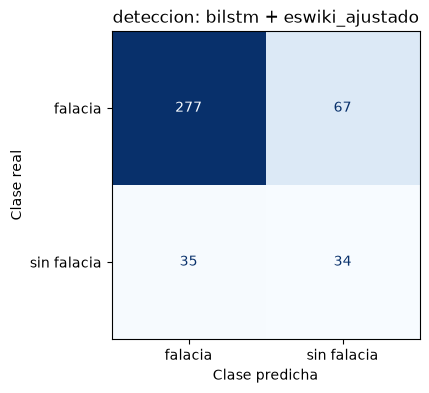

In [13]:
informe("deteccion", (4, 4))

### 6.2. Tipo

tipo: bilstm + eswiki_congelado (semilla 0), test de Political

                           precision    recall  f1-score   support

               ad_hominem      0.478     0.493     0.485        67
               ad_populum      0.200     0.500     0.286         6
        apelacion_emocion      0.286     0.269     0.277        52
       deduccion_invalida      0.040     0.077     0.053        13
              distraccion      0.000     0.000     0.000         9
     falacia_credibilidad      0.333     0.357     0.345        14
         falsa_causalidad      0.378     0.280     0.322        50
             falso_dilema      0.342     0.591     0.433        22
generalizacion_apresurada      0.111     0.056     0.074        18
           hombre_de_paja      0.286     0.189     0.228        74
             otra_falacia      0.242     0.421     0.308        19

                 accuracy                          0.308       344
                macro avg      0.245     0.294     0.255       

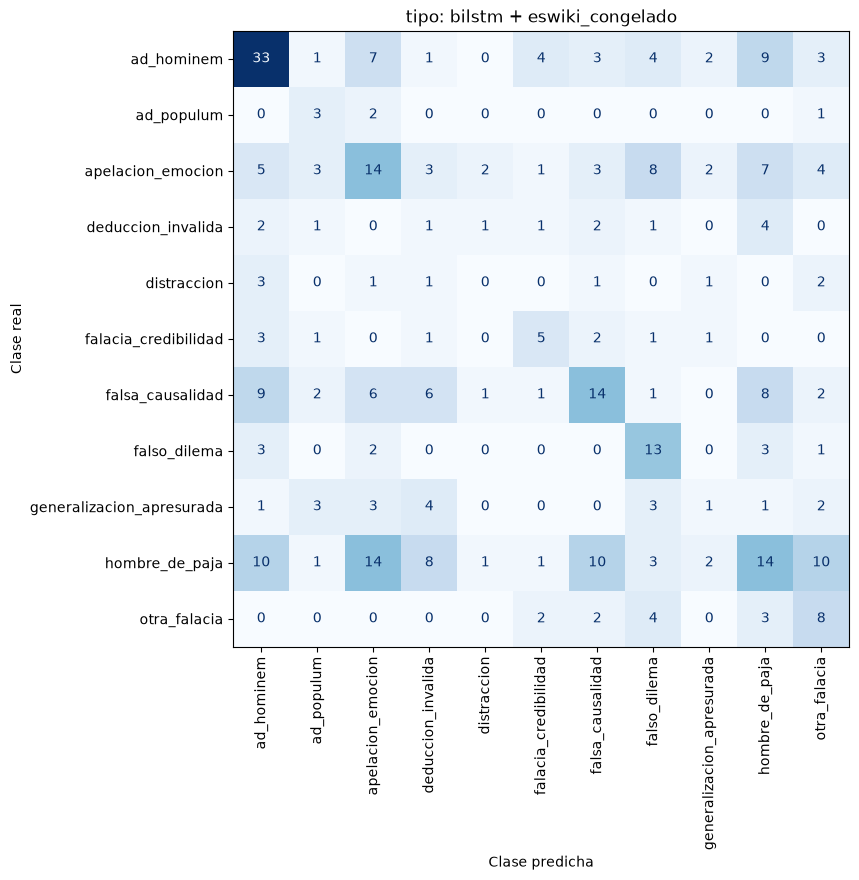

In [14]:
informe("tipo", (8, 8))

## 7. Referencia del artículo de FallacyES

El artículo da, con un split al azar (algo optimista):
- Tipo, en prototípicas: F1 ponderado 0,39 (TF-IDF + regresión logística) y 0,68 (RoBERTa).
- Detección, en espontáneas: F1 de la clase falacia 0,66 y 0,88.

No son directamente comparables con las de aquí: son otros corpus y otro split, y nuestro test es el de Political.